# Assignment 1: Basic EDA

1. Read in the "Computers.csv" file. 
2. Explore the **target variable, "price"**. Look at a `histogram` and `boxplot` of it.
3. Then, produce `histograms` of the **'speed'** and **'ram'** variables. 
4. Feel free to further explore the dataset!

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
computers = pd.read_csv("../datasets/Computers.csv")

computers.head()

,price,speed,hd,ram,screen,cd,multi,premium,ads,trend
0,1499,25,80,4,14,no,no,yes,94,1
1,1795,33,85,2,14,no,no,yes,94,1
2,1595,25,170,4,15,no,no,yes,94,1
3,1849,25,170,8,14,no,no,no,94,1
4,3295,33,340,16,14,no,no,yes,94,1


In [3]:
computers.info()

<class 'pandas.DataFrame'>
RangeIndex: 6259 entries, 0 to 6258
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   price    6259 non-null   int64
 1   speed    6259 non-null   int64
 2   hd       6259 non-null   int64
 3   ram      6259 non-null   int64
 4   screen   6259 non-null   int64
 5   cd       6259 non-null   str  
 6   multi    6259 non-null   str  
 7   premium  6259 non-null   str  
 8   ads      6259 non-null   int64
 9   trend    6259 non-null   int64
dtypes: int64(7), str(3)
memory usage: 489.1 KB


In [4]:
computers.describe().T.round()

,count,mean,std,min,25%,50%,75%,max
price,6259.0,2220.0,581.0,949.0,1794.0,2144.0,2595.0,5399.0
speed,6259.0,52.0,21.0,25.0,33.0,50.0,66.0,100.0
hd,6259.0,417.0,259.0,80.0,214.0,340.0,528.0,2100.0
ram,6259.0,8.0,6.0,2.0,4.0,8.0,8.0,32.0
screen,6259.0,15.0,1.0,14.0,14.0,14.0,15.0,17.0
ads,6259.0,221.0,75.0,39.0,162.0,246.0,275.0,339.0
trend,6259.0,16.0,8.0,1.0,10.0,16.0,22.0,35.0


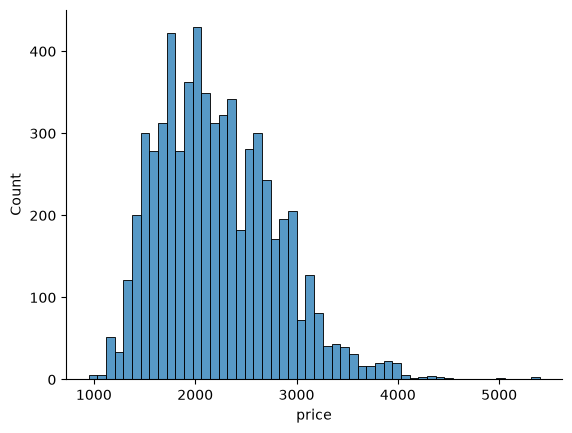

In [5]:
# 2.1. Histogram of Price
sns.histplot(x=computers.price)
sns.despine()

>The `mean` and `median` are close to 2100.
>
>The distribution of prices shows a right skewed plot

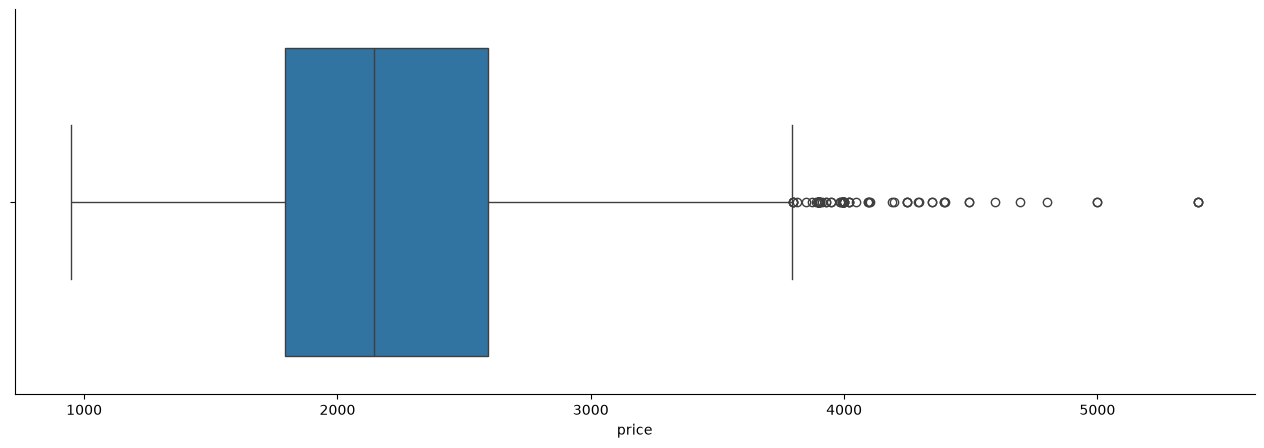

In [6]:
# 2.2 Boxplot of Price
plt.figure(figsize=(16, 5))
sns.boxplot(x=computers.price)
sns.despine()

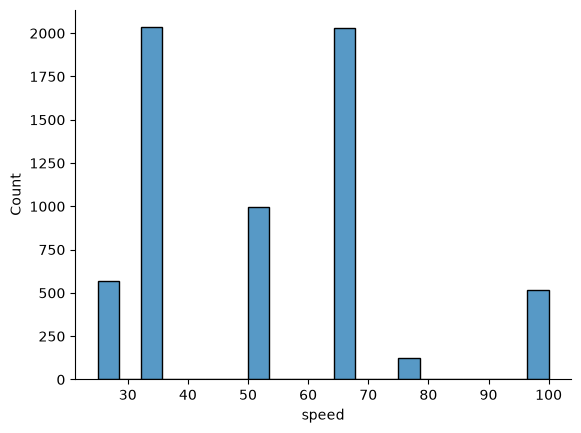

In [7]:
# 3.1. Histogram of the Feature Speed
sns.histplot(x=computers.speed)
sns.despine()

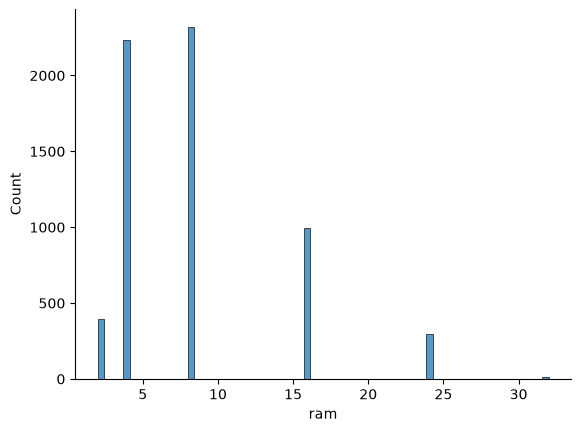

In [8]:
# 3.2. Histogram of the Feature RAM
sns.histplot(x=computers.ram)
sns.despine()

> The upper two plots (*speed and ram*) show us that both plots have no normal distribution behaviour.
>
> We'll need to check `speed` and `ram` later on Feature Engineering.

---

<br><br>

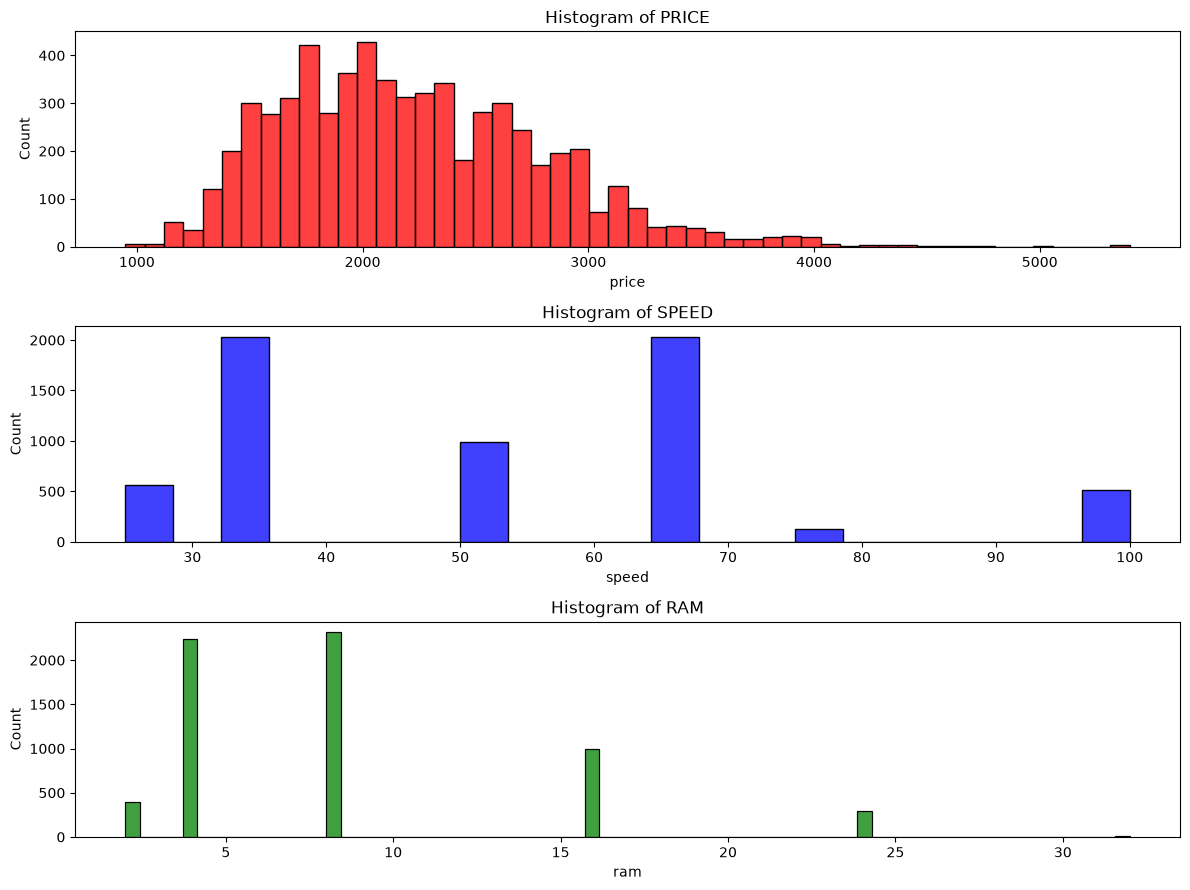

In [9]:
# Let's create a loop to reduce some time

columns = ['price', 'speed', 'ram']
color = ['r', 'b', 'g']
data = computers

fig, ax = plt.subplots(len(columns), figsize=(12, 9), layout='tight')

for col, c, ax in zip(columns, color, ax.flat):
    sns.histplot(data=data, x=col, ax=ax, color=c)
    ax.set_title(f"Histogram of {col.upper()}")

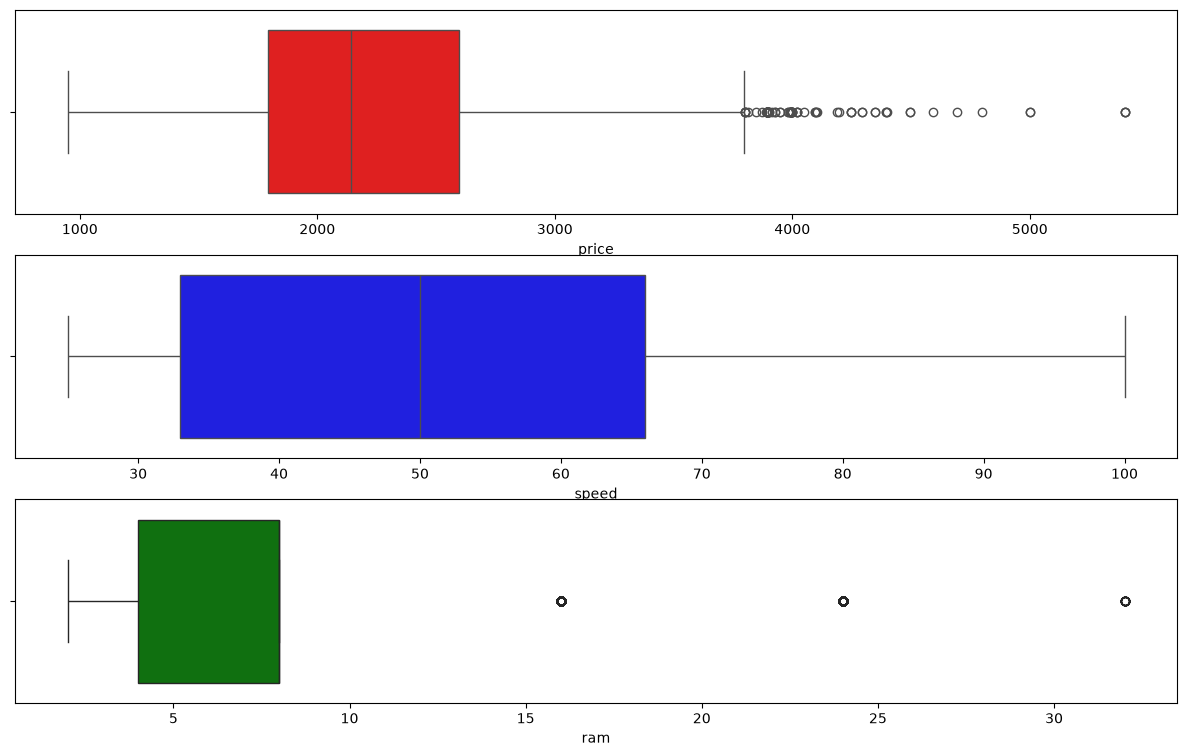

In [10]:
fig, ax = plt.subplots(nrows=3, figsize=(15, 9))

for col, c, ax in zip(columns, color, ax.flat):
    sns.boxplot(data=data, x=col, ax=ax, color=c)

<br><br>

---

## Assignment 2: Variable Relationships

1. Build a **correlation matrix** of numeric features and pass it into a **heatmap**

2. Build a **pairplot** of numeric features in the data. Hint: `df.select_dtypes("number")` selects numeric columns. Consider sampling with `df.sample(1000)` to speed this up if it takes too long.

3. Build an **lmplot** of `ram vs. price`. Does being a premium model (premium == 'yes') impact this relationship?

<br>

<br><br>

---

### 1. Correlation Matrix & Heatmap

<br>

In [14]:
proj_corr = computers.corr(numeric_only=True)
proj_corr

,price,speed,hd,ram,screen,ads,trend
price,1.000000,0.300976,0.430258,0.622748,0.296041,0.054540,-0.199987
speed,0.300976,1.000000,0.372304,0.234760,0.189074,-0.215232,0.405438
hd,0.430258,0.372304,1.000000,0.777726,0.232802,-0.323222,0.577790
ram,0.622748,0.234760,0.777726,1.000000,0.208954,-0.181670,0.276844
screen,0.296041,0.189074,0.232802,0.208954,1.000000,-0.093919,0.188614
ads,0.054540,-0.215232,-0.323222,-0.181670,-0.093919,1.000000,-0.318553
trend,-0.199987,0.405438,0.577790,0.276844,0.188614,-0.318553,1.000000


<Axes: >

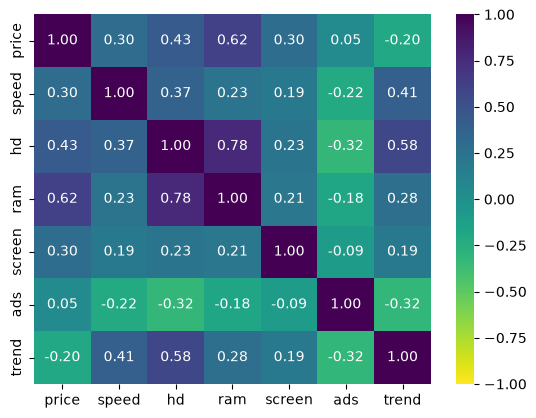

In [21]:
sns.heatmap(data=proj_corr, 
            annot=True, 
            fmt='.2f', 
            cmap='viridis_r', 
            vmin=-1, vmax=1)

<br><br>

---

### 2. Pairplot



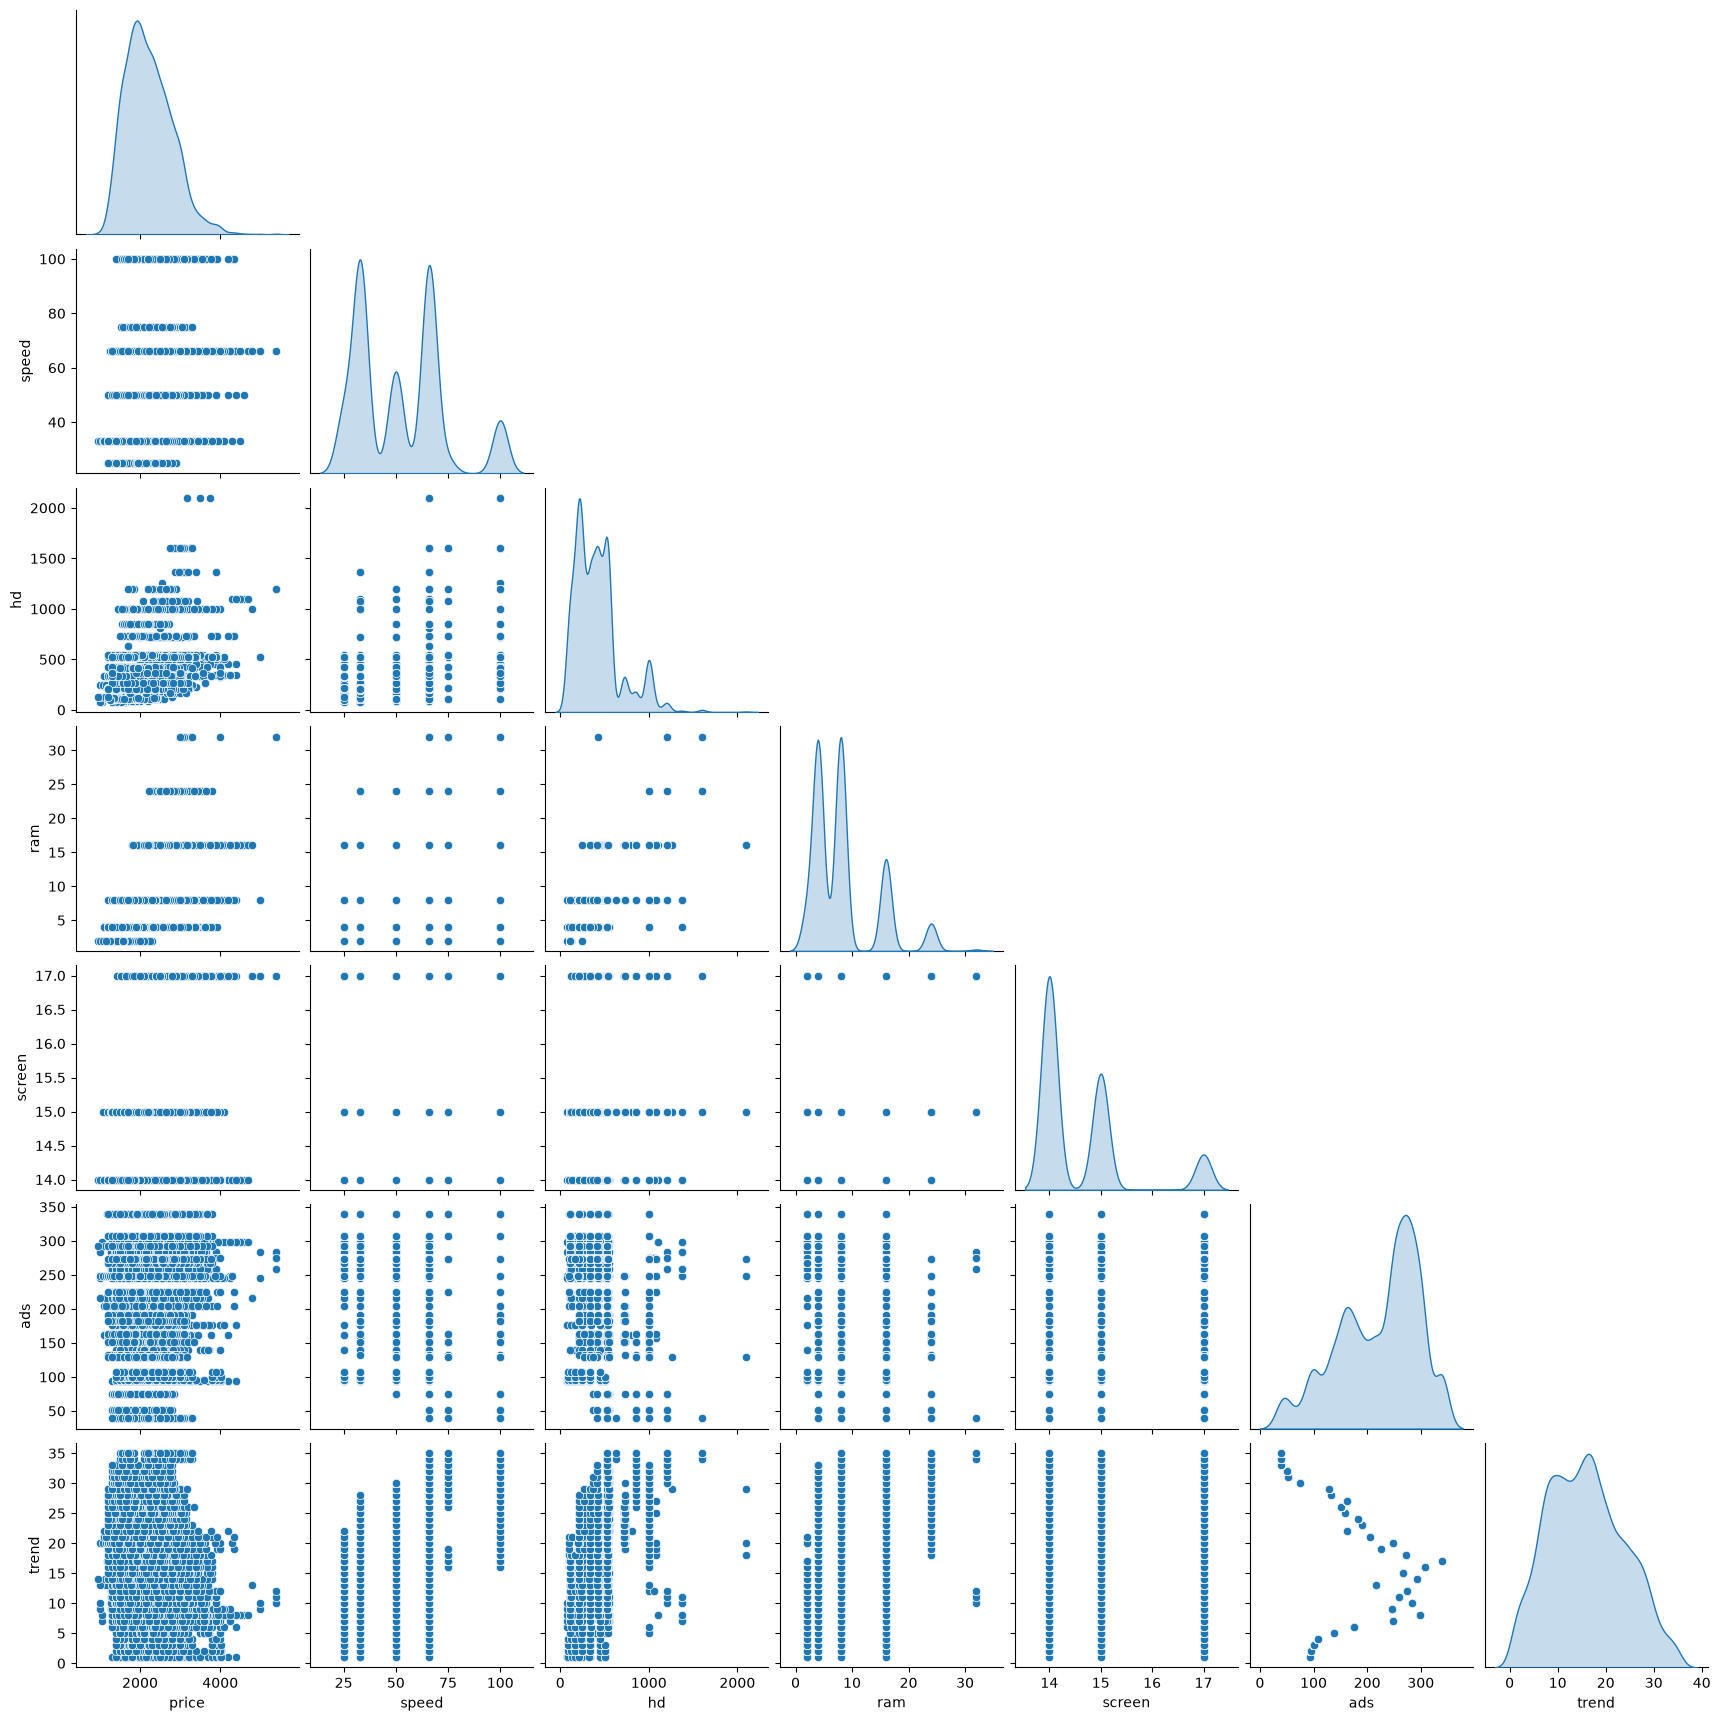

In [23]:
sns.pairplot(data=computers.select_dtypes('number'), corner=True, diag_kind='kde')
sns.despine()

<br><br>

---

### 3. Lmplot

<br>

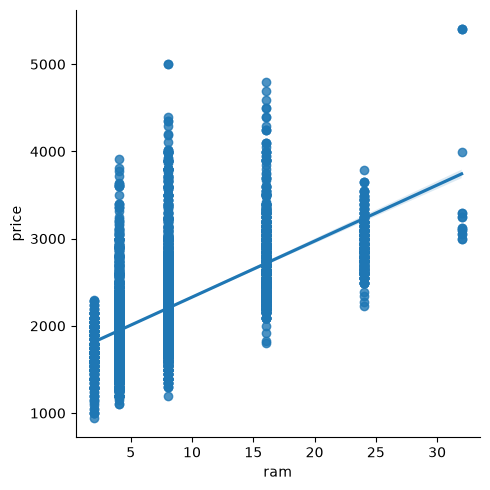

In [25]:
sns.lmplot(data=computers, x='ram', y='price', )
plt.show()

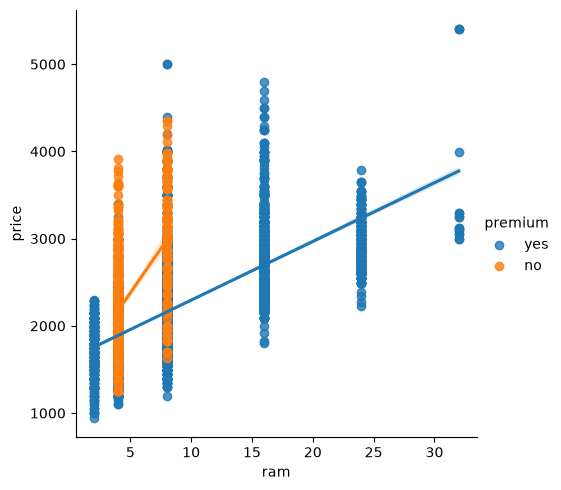

In [27]:
sns.lmplot(data=computers, x='ram', y='price', hue='premium')
plt.show()

>Since the slopes of both groups have different values of RAM, we can not see the relationship between these two groups with this same range of RAM.
>
>We need to re-scale the RAM range in order to see the slope between this two groups within the same range of values...

<br>

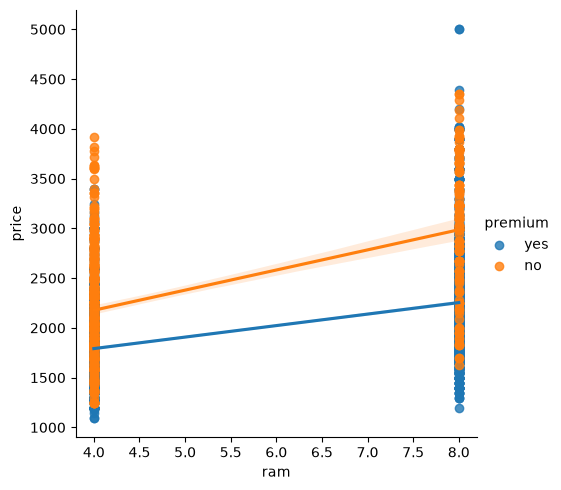

In [29]:
sns.lmplot(data=computers.query("ram > 3 and ram < 10"), x='ram', y='price', hue='premium')
plt.show()

>Now we can make some prior conclusions
>
>- We can apparently conclude that the `premium` data has some noise. Because the price of RAM on PREMIUM computers can't be cheaper than NON-PREMIUM computers.

In [11]:
computers.head()

,price,speed,hd,ram,screen,cd,multi,premium,ads,trend
0,1499,25,80,4,14,no,no,yes,94,1
1,1795,33,85,2,14,no,no,yes,94,1
2,1595,25,170,4,15,no,no,yes,94,1
3,1849,25,170,8,14,no,no,no,94,1
4,3295,33,340,16,14,no,no,yes,94,1
